# GLMExample

Как количество отрезков связано с наличием ограничения параллельности.


`n_lines` количество отрезков.

`has_parallel` наличие ограничения параллельности.

Вероятность оцениваем логистической регрессией.


### Запуск

Python 3.12. Версии библиотек в `uv.lock`.

```bash
uv sync
uv run jupyter lab glm_parallelism.ipynb
```

Локальный uv находится в `.tools/uv`.

Библиотека SketchGraphs нужна в `../external/CPTSketchGraphs/SketchGraphs/sketchgraphs`.


In [1]:
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import statsmodels.api as sm
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sketchgraphs.data import ConstraintType, EdgeOp, EntityType, NodeOp
from sketchgraphs.data import flat_array

print(f"Python {sys.version.split()[0]} · окружение готово")
display(pd.Series(
    {name: version(name) for name in (
        "numpy", "pandas", "matplotlib", "statsmodels", "scikit-learn", "sketchgraphs"
    )},
    name="Версия",
).to_frame())


Python 3.12.3 · окружение готово


,Версия
numpy,1.26.4
pandas,2.3.3
matplotlib,3.11.2
statsmodels,0.14.6
scikit-learn,1.9.1
sketchgraphs,0.1


In [2]:
RANDOM_STATE = 42
N_SKETCHES = 1_000
DATA_PATH = Path("../cptsketchgraphs.npy")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
    "font.size": 11,
})
pd.set_option("display.max_columns", 10)


### Данные

Берём по одному варианту из 1000 непустых групп CPTSketchGraphs.


In [3]:
dataset = flat_array.load_dictionary_flat(str(DATA_PATH))
groups = dataset["perturbations"]
rng = np.random.default_rng(RANDOM_STATE)
candidate_indices = rng.permutation(len(groups))

group_indices = []
sequences = []
for group_index in candidate_indices:
    variants = groups[int(group_index)]
    if not variants:
        continue
    group_indices.append(int(group_index))
    sequences.append(variants[int(rng.integers(len(variants)))])
    if len(sequences) == N_SKETCHES:
        break

if len(sequences) < N_SKETCHES:
    raise ValueError("Недостаточно непустых групп")

print(f"Групп в файле {len(groups)}")
print(f"Эскизов в выборке {len(sequences)}")

n_lines = [
    sum(isinstance(op, NodeOp) and op.label == EntityType.Line for op in sequence)
    for sequence in sequences
]

has_parallel = [
    int(any(isinstance(op, EdgeOp) and op.label == ConstraintType.Parallel for op in sequence))
    for sequence in sequences
]

df = pd.DataFrame(
    {"n_lines": n_lines, "has_parallel": has_parallel},
    index=pd.Index(group_indices, name="sketch_id"),
)
display(df.head())


Групп в файле 1643604
Эскизов в выборке 1000


,n_lines,has_parallel
sketch_id,,
431388,8,1
1195462,8,0
575315,7,1
242680,9,1
126579,5,1


### Количество отрезков


,Значение
count,1000.000000
mean,7.083000
std,3.444993
min,0.000000
25%,4.000000
50%,7.000000
75%,8.000000
max,16.000000


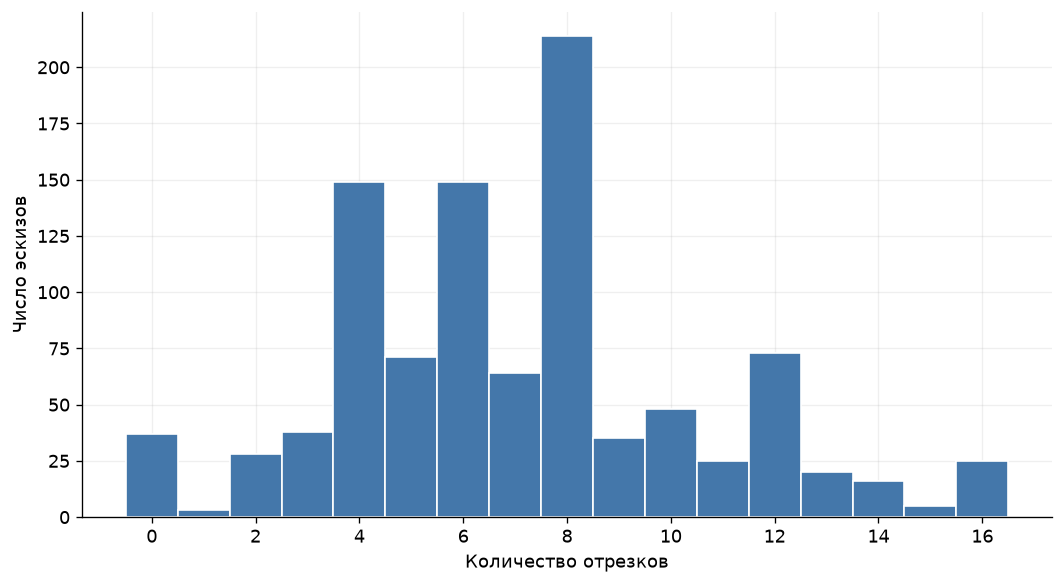

In [4]:
display(df["n_lines"].describe().to_frame("Значение"))

fig, ax = plt.subplots()
ax.hist(
    df["n_lines"],
    bins=np.arange(df["n_lines"].max() + 2) - 0.5,
    color="#4477aa",
    edgecolor="white",
)
ax.set(xlabel="Количество отрезков", ylabel="Число эскизов")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


### Доля эскизов с параллельностью


In [5]:
parallel_count = int(df["has_parallel"].sum())
parallel_share = df["has_parallel"].mean()
print(f"С параллельностью {parallel_count} из {len(df)} эскизов ({parallel_share:.1%})")


С параллельностью 553 из 1000 эскизов (55.3%)


### Обучение и оценка GLM


In [6]:
X = sm.add_constant(df[["n_lines"]], has_constant="add")
X_train, X_test, y_train, y_test = train_test_split(
    X, df["has_parallel"], test_size=0.2,
    random_state=RANDOM_STATE, stratify=df["has_parallel"],
)
glm = sm.GLM(y_train, X_train, family=sm.families.Binomial()).fit()

coefficients = pd.DataFrame({"Коэффициент": glm.params, "p": glm.pvalues})
intervals = glm.conf_int()
intervals.columns = ["Нижняя граница", "Верхняя граница"]
display(coefficients.join(intervals).round(4))

test_probability = glm.predict(X_test)
baseline_probability = np.full(len(y_test), y_train.mean())
rows = []
for name, probabilities in [("GLM", test_probability), ("Частота класса", baseline_probability)]:
    rows.append({
        "Модель": name,
        "Log loss": log_loss(y_test, probabilities),
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "Точность": accuracy_score(y_test, probabilities >= 0.5),
    })
evaluation = pd.DataFrame(rows).set_index("Модель")
display(evaluation.round(4))


,Коэффициент,p,Нижняя граница,Верхняя граница
const,-0.9852,0.0,-1.3374,-0.6331
n_lines,0.1740,0.0,0.1263,0.2216


,Log loss,ROC AUC,Точность
Модель,,,
GLM,0.6443,0.6613,0.630
Частота класса,0.6871,0.5000,0.555


### Фактические доли и прогноз модели

Доли по 1000 эскизам. Модель обучена на 800. Площадь точки пропорциональна числу эскизов.

Линейный предиктор $\eta=\beta_0+\beta_1 n$.

Функция связи $g(p)=\operatorname{logit}(p)$.

Условное среднее $\mathbb{E}[Y\mid n]=p=\frac{\exp(\eta)}{1+\exp(\eta)}$.


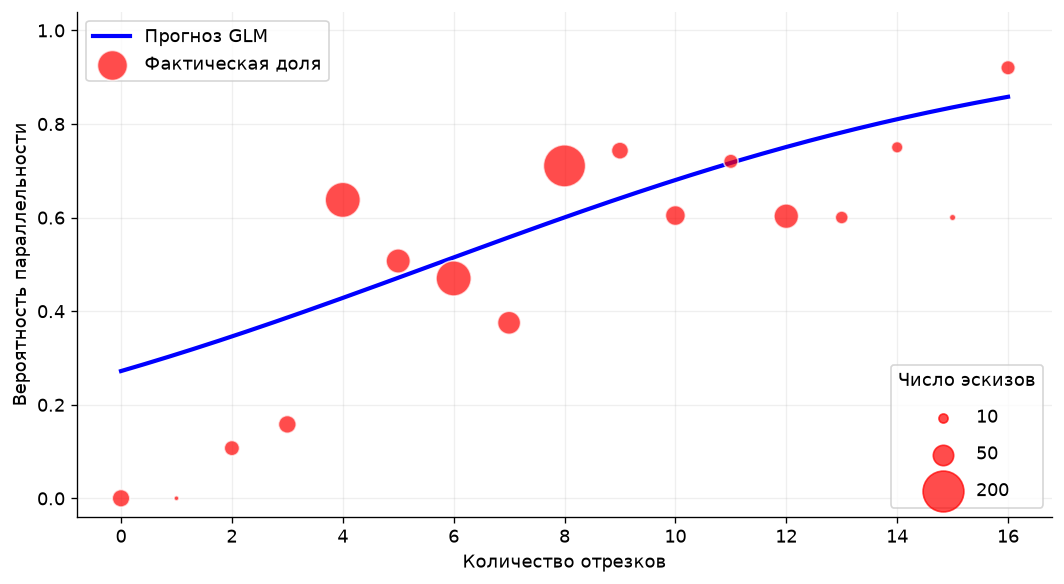

In [7]:
observed = df.groupby("n_lines")["has_parallel"].agg(["mean", "size"])
n = np.linspace(df["n_lines"].min(), df["n_lines"].max(), 300)
grid = sm.add_constant(pd.DataFrame({"n_lines": n}), has_constant="add")
eta = grid @ glm.params
probability = glm.family.link.inverse(eta)

prob_fig, prob_ax = plt.subplots()
prob_ax.plot(n, probability, color="blue", linewidth=2.5, label="Прогноз GLM")
points = prob_ax.scatter(
    observed.index, observed["mean"], s=3 * observed["size"],
    color="red", alpha=0.7, edgecolors="white", label="Фактическая доля", zorder=3,
)
prob_ax.set(xlabel="Количество отрезков", ylabel="Вероятность параллельности", ylim=(-0.04, 1.04))
prob_ax.set_yticks(np.linspace(0, 1, 6))
prob_ax.xaxis.set_major_locator(MaxNLocator(integer=True))
prob_ax.set_axisbelow(True)
series_legend = prob_ax.legend(loc="upper left")
size_legend = [prob_ax.scatter([], [], s=3 * count, color="red", alpha=0.7) for count in (10, 50, 200)]
prob_ax.add_artist(series_legend)
prob_ax.legend(size_legend, ["10", "50", "200"], title="Число эскизов", loc="lower right", labelspacing=1)
prob_fig.tight_layout()
plt.show()


### Выводы

Вероятность по модели растёт с числом отрезков. Фактические доли отклоняются от кривой. Одного признака для точного прогноза мало. Вывод относится к этой выборке CPTSketchGraphs.
